In [ ]:
# used for continuous numerical values

### Simple Linear Regression
one independent variable and continuous dependent variable

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

data = pd.read_csv("StudentPerformance.csv")

In [3]:
print(data.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [4]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               999 non-null    str    
 2   parental level of education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test preparation course      999 non-null    str    
 5   math score                   998 non-null    float64
 6   reading score                998 non-null    float64
 7   writing score                998 non-null    float64
dtypes: float64(3), str(5)
memory usage: 62.6 KB
None


In [5]:
print(data.shape)

(1000, 8)


In [6]:
print(data.describe())

       math score  reading score  writing score
count  998.000000     998.000000     998.000000
mean    66.074148      69.149299      68.057114
std     15.174628      14.577870      15.198709
min      0.000000      17.000000      10.000000
25%     57.000000      59.000000      58.000000
50%     66.000000      70.000000      69.000000
75%     77.000000      79.000000      79.000000
max    100.000000     100.000000     100.000000


In [7]:
data.isnull().sum()

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     2
reading score                  2
writing score                  2
dtype: int64

In [8]:
data.duplicated().sum()
data["math score"].unique()  # to detect the incorrect values

array([ 72.,  69.,  90.,  47.,  76.,  71.,  88.,  40.,  64.,  38.,  58.,
        65.,  78.,  50.,  18.,  46.,  54.,  66.,  44.,  74.,  73.,  67.,
        70.,  62.,  63.,  56.,  97.,  81.,  75.,  57.,  55.,  53.,  59.,
        82.,  77.,  33.,  52.,   0.,  79.,  39.,  45.,  60.,  61.,  41.,
        49.,  30.,  80.,  42.,  27.,  43.,  68.,  85.,  98.,  87.,  51.,
        99.,  84.,  91.,  83.,  89.,  22., 100.,  96.,  94.,  48.,  35.,
        34.,  86.,  92.,  37.,  28.,  24.,  nan,  26.,  95.,  36.,  29.,
        32.,  93.,  19.,  23.,   8.])

In [9]:
data["race/ethnicity"] = data["race/ethnicity"].fillna(data["race/ethnicity"].mode()[0])
data["test preparation course"] = data["test preparation course"].fillna(data["test preparation course"].mode()[0])
data["math score"] = pd.to_numeric(data["math score"], errors = "coerce")
data["math score"] = data["math score"].fillna(data["math score"].mean())
data["reading score"] = pd.to_numeric(data["reading score"], errors = "coerce")
data["reading score"] = data["reading score"].fillna(data["reading score"].mean())
data["writing score"] = data["writing score"].fillna(data["writing score"].mean())
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [10]:
data["race/ethnicity"].unique()
data["race/ethnicity"] = data["race/ethnicity"].fillna(
    data["race/ethnicity"].mode()[0]
)

In [11]:
encoder = LabelEncoder()

data["race/ethnicity"] = encoder.fit_transform(data["race/ethnicity"])

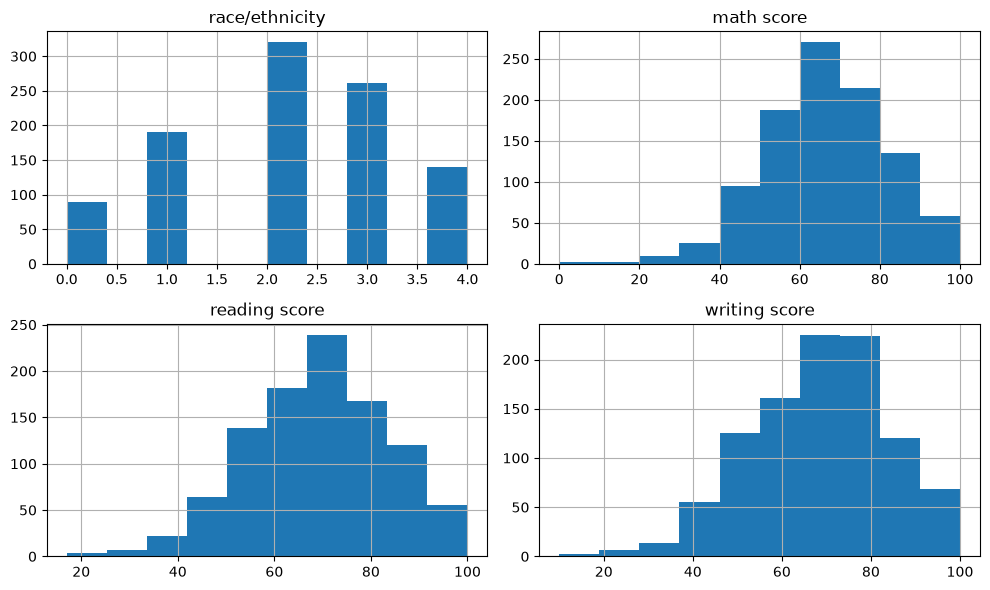

In [12]:
#Understand data distribution
data.hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

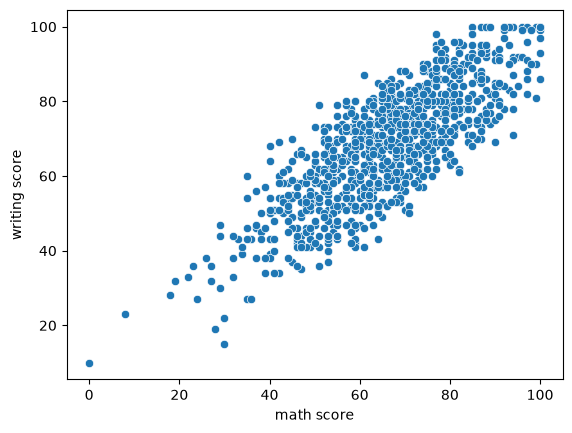

In [13]:
#Check linear relationship
#visualize relationship between input and other features  ->relaion must be linear
sns.scatterplot(
    data=data,
    x="math score",
    y="writing score"
)
plt.show()

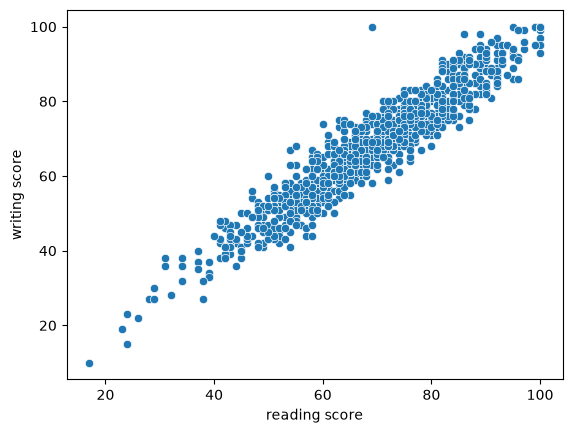

In [14]:
sns.scatterplot(
    data=data,
    x="reading score",
    y="writing score"
)
plt.show()

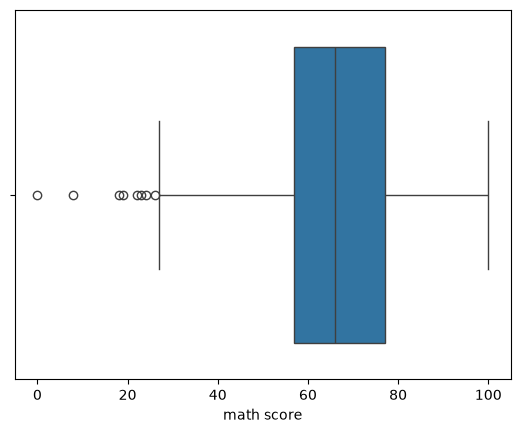

In [15]:
#Detect unusual values
sns.boxplot(data=data, x="math score")
plt.show()

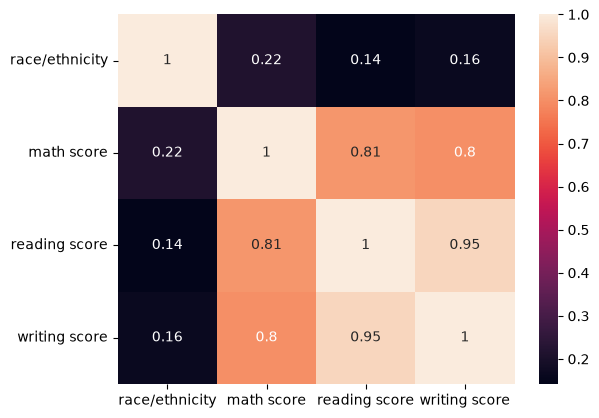

In [16]:
#Understand feature relationships - Corelation
numeric_data = data.select_dtypes(
    include="number"
)

sns.heatmap(
    numeric_data.corr(),
    annot=True
)

plt.show()

In [17]:
x = data[["math score", "reading score", "race/ethnicity"]]
y = data["writing score"]

# hold out cross validation technique (train and test data or validation data)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=40
)

In [18]:
model = LinearRegression()
model.fit(x_train, y_train)
print("intercept : ", model.intercept_)
print("coefficient : ", model.coef_)

intercept :  -1.5855369457486574
coefficient :  [0.06818946 0.93216798 0.22949663]


In [19]:
y_pred = model.predict(x_test)

In [20]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

print("y_test dimensions:", y_test.ndim)
print("y_pred dimensions:", y_pred.ndim)

y_test shape: (200,)
y_pred shape: (200,)
y_test dimensions: 1
y_pred dimensions: 1


In [21]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual  Predicted
204    42.0  41.115522
71     63.0  54.668128
594    99.0  98.363685
672    76.0  76.287632
14     58.0  51.228839


In [22]:
# save the model
joblib.dump(model, "Linear_Reg_Model.pkl")

['Linear_Reg_Model.pkl']

In [23]:
loaded_model = joblib.load("Linear_Reg_Model.pkl")
new_data = pd.DataFrame({
    "math score" : [60],
    "reading score" : [70],
    "race/ethnicity" : [1]
})
prediction = loaded_model.predict(new_data)
print(prediction)

[67.98708609]


#### Evaluate the model

In [25]:
print("MAE:", mean_absolute_error(y_test, y_pred))  # mean of absolute error -> |actual - predicted | ->Lower is better
print("MSE:", mean_squared_error(y_test, y_pred)) # large errors contribute more heavily. -> Lower is better - sensitive to outliers
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred))) #Lower is better
print("R2:", r2_score(y_test, y_pred)) #higher is better

MAE: 4.152304721971961
MSE: 29.339786375884305
RMSE: 5.4166213063019555
R2: 0.8712376618279456


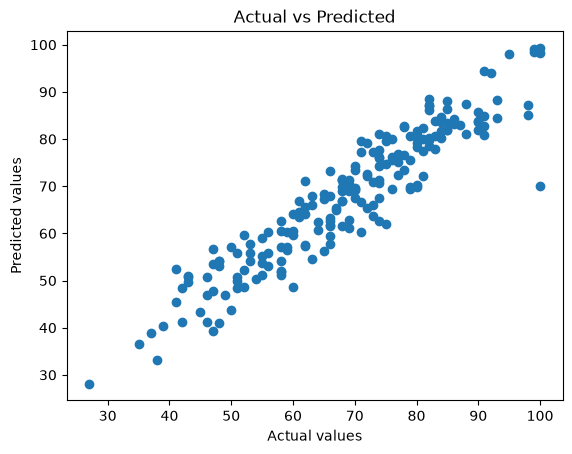

In [26]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted")

plt.show()

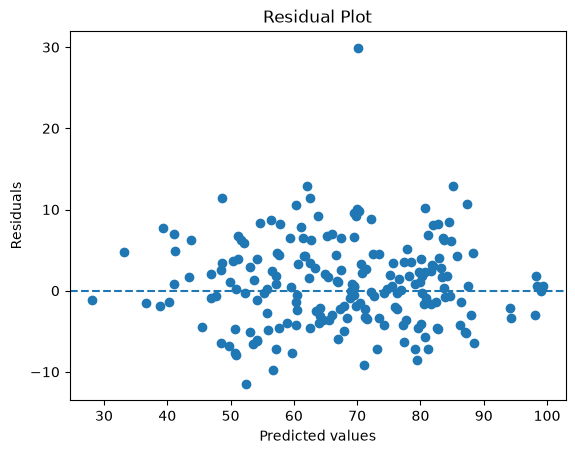

In [27]:
residuals = y_test - y_pred # difference in predictions

plt.scatter(y_pred, residuals) #plot the difference in predictions form actual value, against the predicted value
# good model -> when values are close to zero

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

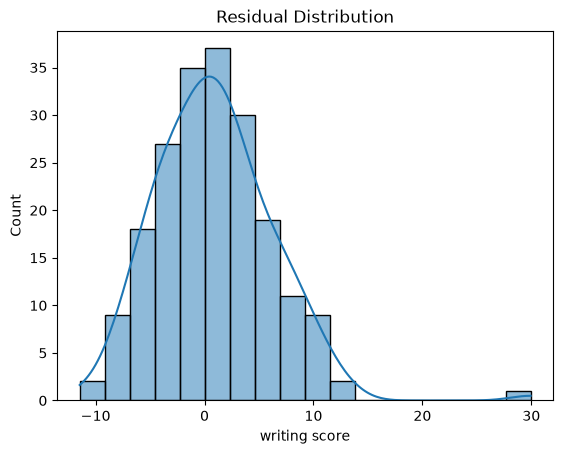

In [28]:
sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.show()

### After removing outliers

In [29]:
Q1 = x_train.quantile(0.25)
Q3 = x_train.quantile(0.75)

IQR = Q3-Q1

lowerLimit = Q1 - 1.5 * IQR
upperLimit = Q3 + 1.5 * IQR           

In [30]:
outlier_mask = (
    (x_train < lowerLimit) |
    (x_train > upperLimit)
).any(axis=1)

print(x_train[outlier_mask])

     math score  reading score  race/ethnicity
601        29.0           29.0               2
466        26.0           31.0               3
787        19.0           38.0               1
145        22.0           39.0               2
810        51.0           31.0               0
980         8.0           24.0               1
59          0.0           17.0               2
17         18.0           32.0               1
327        28.0           23.0               0
76         30.0           26.0               4
338        24.0           38.0               1
596        30.0           24.0               1
211        35.0           28.0               2
842        23.0           44.0               1


In [31]:
x_train_clean = x_train[~outlier_mask]
y_train_clean = y_train.loc[x_train_clean.index]

In [32]:
model = LinearRegression()
model.fit(x_train_clean, y_train_clean)
print("intercept : ", model.intercept_)
print("coefficient : ", model.coef_)

intercept :  -1.022751846005292
coefficient :  [0.05943609 0.93312396 0.22342886]


In [33]:
y_pred = model.predict(x_test)

In [34]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual  Predicted
204    42.0  41.188918
71     63.0  54.713826
594    99.0  98.204622
672    76.0  76.308865
14     58.0  51.404622


In [36]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

MAE: 4.1446418830368055
MSE: 29.307999615086985
RMSE: 5.413686324039007
R2: 0.8713771631041561
